Imporitng lib's

In [14]:
import pandas as pd
from pathlib import Path as P
import numpy as np
import matplotlib as mpl
import seaborn as sb

In [15]:
try :
    dir = P(__file__).resolve().parent
except NameError:
    dir = P.cwd()
file_path = dir / "data"
df = pd.read_csv(file_path / "clean_games.csv", parse_dates=["Release Date"])

<Axes: xlabel='Release Year'>

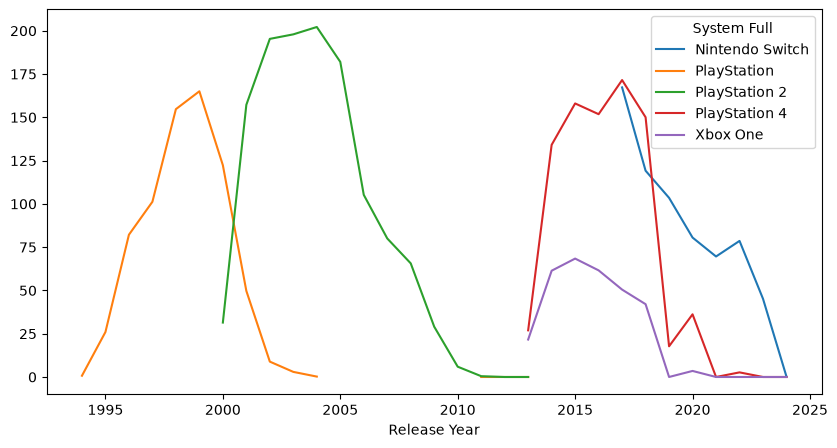

In [16]:
top = df["System Full"].value_counts().head(5).index
pivot = (df[df["System Full"].isin(top)]
         .pivot_table(
             index="Release Year",
               columns="System Full",
               values="Units(m)",
               aggfunc="sum"))
pivot.plot(figsize=(10,5))

In [17]:
conditions = [
    df["System Full"].str.contains("PlayStation|PS|VIST|PSP",case=False , na=False),
    df["System Full"].str.contains("Xbox|X360|Xone",case=False,na=False),
    df["System Full"].str.contains("Nintendo|Wii|Switch",case=False,na=False),
    df["System Full"].str.contains("Sega|Genesis|Dreamcast|Saturn",case=False,na=False)
]
brands = [ "Sony" , "Microsoft","Nintendo","Sega"]
df["Brands"]= np.select(conditions,brands,default="Other")

In [27]:
# Create a 2D table
lib = df.dropna(subset="Release Year").copy()
lib["Release Year"] = lib["Release Year"].astype(int)
counts = lib.groupby(["System Full","Release Year"]).size().unstack(fill_value=0)
counts

Release Year,1977,1978,1979,1980,1981,1982,1983,1984,1985,1986,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
System Full,,,,,,,,,,,,,,,,,,,,,
Atari 2600,10,45,2,10,20,145,178,24,1,2,...,0,0,0,0,0,0,0,0,0,0
Atari 5200/7800,0,0,0,0,1,8,38,22,0,2,...,0,0,0,0,0,0,0,0,0,0
GameCube,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Intellivision,0,0,0,19,7,29,47,0,2,5,...,0,0,0,0,0,0,0,0,0,0
Nintendo 64,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Nintendo Entertainment System,0,0,0,0,0,0,2,5,43,55,...,0,0,0,0,0,2,0,0,0,0
Nintendo Switch,0,0,0,0,0,0,0,0,0,0,...,1,0,345,515,383,254,87,36,24,5
PlayStation,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
PlayStation 2,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,4,0,0,0,0


In [39]:
table = lib.pivot_table(index="Release Year",columns="Brands",values="Game Name",aggfunc="count",fill_value=0)
table

Brands,Microsoft,Nintendo,Other,Sega,Sony
Release Year,,,,,
1977,0,0,10,0,0
1978,0,0,45,0,0
1979,0,0,2,0,0
1980,0,0,29,0,0
1981,0,0,28,0,0
1982,0,0,182,0,0
1983,0,2,263,0,0
1984,0,5,46,0,0
1985,0,43,3,4,0


<Axes: xlabel='Release Year'>

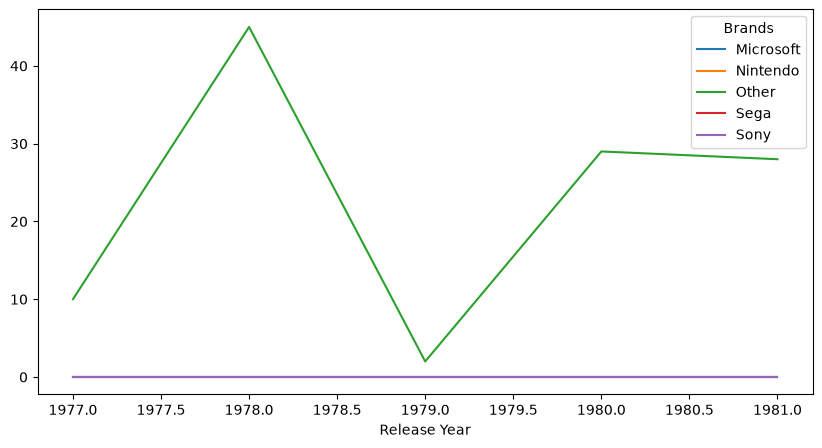

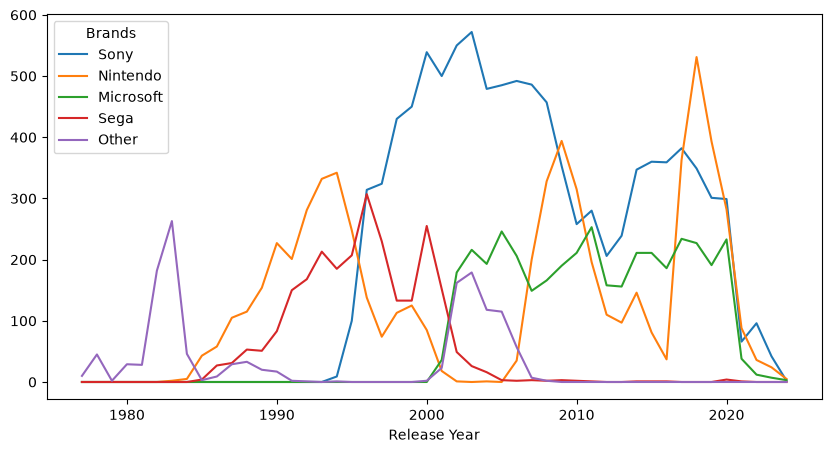

In [ ]:
table.head(5).plot(figsize=(10,5))   # here we have an issue 
# Let's fix it
top = lib["Brands"].value_counts().head(5).index
table[top].plot(figsize=(10,5))

In [19]:
(df.groupby("System Full")["Units(m)"].apply(lambda s:s.isna().mean()*100)).sort_values()

System Full
Xbox                              14.969450
GameCube                          15.082956
Nintendo 64                       17.571059
Wii                               18.622754
Xbox 360                          24.508671
PlayStation 3                     27.666315
PlayStation 2                     37.313433
PlayStation                       55.233853
PlayStation 4                     69.228285
Wii U                             71.066908
Xbox One                          72.931206
Atari 2600                        73.185484
Sega Saturn                       76.086957
Super Nintendo                    79.867440
Nintendo Switch                   85.140226
Nintendo Entertainment System     89.954751
Sega Dreamcast                    91.883614
Intellivision                     94.029851
Sega Genesis                      95.522388
Atari 5200/7800                   99.180328
Sega Master System               100.000000
Name: Units(m), dtype: float64